# Frequency analysis

This example computes the natural frequencies and modes of plates, with and without an in-plane pre-stress. It checks the isotropic plate against the closed-form solution of a simply supported plate, then analyses a laminated plate with the nine models of `panels` that the example compares.

The kinetic energy gives the mass matrix $\boldsymbol{M}$, `Shell.calc_kM`. For harmonic motion, $\boldsymbol{c}(t) = \boldsymbol{c}\, e^{i\omega t}$, the equations of motion become the eigenvalue problem

$$
(\boldsymbol{K} + \lambda^2 \boldsymbol{M})\boldsymbol{c} = \boldsymbol{0}, \qquad \lambda^2 = -\omega_n^2,
$$

solved with `structsolve.freq`, which returns the eigenvalues $\lambda^2$ and the modes. $\omega_n$ is the natural frequency in rad/s. A pre-stress is included by adding the geometric stiffness matrix to the constitutive one, $\boldsymbol{K} = \boldsymbol{K}_C + \boldsymbol{K}_G$: compressive stress resultants lower the frequencies, and tensile ones raise them.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from structsolve import freq
from panels.shell import Shell


def results_table(rows):
    """Markdown table of (quantity, panels, reference, source) rows"""
    out = ['| quantity | panels | reference | relative difference | reference source |',
           '|---|---|---|---|---|']
    for name, val, ref, src in rows:
        out.append('| %s | %.6g | %.6g | %+.2e | %s |'
                   % (name, val, ref, (val - ref)/abs(ref), src))
    display(Markdown('\n'.join(out)))

## Check against the closed form of a simply supported isotropic plate

For a simply supported isotropic plate the modes are $w = \sin(m\pi x/a)\sin(n\pi y/b)$ (Leissa, 1973). Substituting them into the plate equation with the constant membrane resultants $N_{xx}$ and $N_{yy}$, positive in tension,

$$
D \nabla^4 w - N_{xx} w_{,xx} - N_{yy} w_{,yy} + \rho h \ddot{w} = 0,
$$

gives

$$
\omega_{mn}^2 = \frac{1}{\rho h}\left[ D \pi^4 \left(\frac{m^2}{a^2} + \frac{n^2}{b^2}\right)^2 + N_{xx}\frac{m^2\pi^2}{a^2} + N_{yy}\frac{n^2\pi^2}{b^2}\right],
$$

whose lowest value is the first natural frequency. The in-plane inertia does not enter, since the membrane and bending problems of a flat isotropic plate are uncoupled.

In [2]:
E, nu, h, rho = 70e9, 0.33, 2e-3, 2700.
a, b = 1., 0.5
D = E*h**3/(12*(1 - nu**2))


def omega_closed_form(Nxx, Nyy, nmax=6):
    m, n = np.meshgrid(np.arange(1, nmax + 1), np.arange(1, nmax + 1))
    w2 = (D*np.pi**4*(m**2/a**2 + n**2/b**2)**2
          + Nxx*m**2*np.pi**2/a**2 + Nyy*n**2*np.pi**2/b**2)/(rho*h)
    return np.sqrt(w2.min())


rows = []
for Nxx, Nyy in ((0., 0.), (-200., -50.)):
    s = Shell(model='plate_clpt_donnell', a=a, b=b, stack=[0.], plyt=h,
              laminaprop=(E, nu), rho=rho, m=10, n=10)
    s.Nxx, s.Nyy = Nxx, Nyy
    K = s.calc_kC()
    if Nxx or Nyy:
        K = K + s.calc_kG()
    eigvals, eigvecs = freq(K, s.calc_kM(), sparse_solver=True, silent=True)
    omega = np.sqrt(-eigvals[0]).real
    ref = omega_closed_form(Nxx, Nyy)
    print('Nxx = %g, Nyy = %g N/m: panels %.4f rad/s, closed form %.4f rad/s'
          % (Nxx, Nyy, omega, ref))
    rows.append(('isotropic plate, $N_{xx} = %g$, $N_{yy} = %g$ N/m, $\\omega_1$ (rad/s)'
                 % (Nxx, Nyy), omega, ref, 'closed form (Navier)'))
results_table(rows)

Nxx = 0, Nyy = 0 N/m: panels 153.6772 rad/s, closed form 153.6785 rad/s
Nxx = -200, Nyy = -50 N/m: panels 151.2799 rad/s, closed form 151.2812 rad/s


| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| isotropic plate, $N_{xx} = 0$, $N_{yy} = 0$ N/m, $\omega_1$ (rad/s) | 153.677 | 153.678 | -8.22e-06 | closed form (Navier) |
| isotropic plate, $N_{xx} = -200$, $N_{yy} = -50$ N/m, $\omega_1$ (rad/s) | 151.28 | 151.281 | -8.22e-06 | closed form (Navier) |

## Laminated plate with and without pre-stress

The plate of $1 \times 0.5$ m with the laminate $[0/90/-45/+45]$ of carbon/epoxy plies of 0.125 mm and density 1300 kg/m³ is simply supported. The pre-stress is $N_{xx} = -60$ N/m and $N_{yy} = -5$ N/m. The nine models are the plate and cylindrical-shell models of the classical (CLPT), first-order (FSDT) and third-order (TSDT) shear deformation theories, with a large radius $r = 10^8$ m for the shells. The plate is thin, $a/h = 2000$, so they agree.

The reference values are regression values of the panels unit test `tests/tests_shell/test_natural_frequencies.py`, checked there within 0.1%.

In [3]:
MODELS = ['plate_clpt_donnell', 'cylshell_clpt_donnell',
          'cylshell_clpt_sanders', 'plate_fsdt_donnell', 'plate_tsdt_donnell',
          'cylshell_fsdt_donnell', 'cylshell_fsdt_sanders',
          'cylshell_tsdt_donnell', 'cylshell_tsdt_sanders']
REF = {True: 17.6002, False: 39.1962}
rows = []
first_modes = {}
for model in MODELS:
    for prestress in (False, True):
        p = Shell(model=model, a=1., b=0.5, r=1.e8, stack=[0, 90, -45, +45],
                  plyt=0.125e-3, rho=1.3e3, m=8, n=8,
                  laminaprop=(142.5e9, 8.7e9, 0.28, 5.1e9, 5.1e9, 5.1e9))
        p.Nxx = -60.
        p.Nyy = -5.
        K = p.calc_kC()
        if prestress:
            K = K + p.calc_kG()
        eigvals, eigvecs = freq(K, p.calc_kM(), sparse_solver=True,
                                silent=True)
        omegan = np.sqrt(-eigvals).real
        print('%-22s pre-stress %-5s: first frequencies %s rad/s'
              % (model, prestress, np.round(omegan[:3], 4)))
        rows.append(('`%s`, pre-stress %s' % (model, prestress), omegan[0],
                     REF[prestress],
                     'regression value, `test_natural_frequencies.py`'))
        if model == 'plate_clpt_donnell':
            first_modes[prestress] = (p, eigvecs[:, 0])
results_table(rows)

plate_clpt_donnell     pre-stress False: first frequencies [ 39.1962  72.0131 122.2583] rad/s
plate_clpt_donnell     pre-stress True : first frequencies [17.6002 34.8696 84.4289] rad/s
cylshell_clpt_donnell  pre-stress False: first frequencies [ 39.1962  72.0131 122.2583] rad/s
cylshell_clpt_donnell  pre-stress True : first frequencies [17.6002 34.8696 84.4289] rad/s
cylshell_clpt_sanders  pre-stress False: first frequencies [ 39.1962  72.0131 122.2583] rad/s
cylshell_clpt_sanders  pre-stress True : first frequencies [17.6002 34.8696 84.4289] rad/s


plate_fsdt_donnell     pre-stress False: first frequencies [ 39.196   72.0122 122.2562] rad/s
plate_fsdt_donnell     pre-stress True : first frequencies [17.5997 34.8678 84.4246] rad/s


plate_tsdt_donnell     pre-stress False: first frequencies [ 39.196   72.0123 122.2564] rad/s
plate_tsdt_donnell     pre-stress True : first frequencies [17.5997 34.868  84.425 ] rad/s
cylshell_fsdt_donnell  pre-stress False: first frequencies [ 39.196   72.0122 122.2562] rad/s


cylshell_fsdt_donnell  pre-stress True : first frequencies [17.5997 34.8678 84.4246] rad/s
cylshell_fsdt_sanders  pre-stress False: first frequencies [ 39.196   72.0122 122.2562] rad/s


cylshell_fsdt_sanders  pre-stress True : first frequencies [17.5997 34.8678 84.4246] rad/s
cylshell_tsdt_donnell  pre-stress False: first frequencies [ 39.196   72.0123 122.2564] rad/s
cylshell_tsdt_donnell  pre-stress True : first frequencies [17.5997 34.868  84.425 ] rad/s


cylshell_tsdt_sanders  pre-stress False: first frequencies [ 39.196   72.0123 122.2564] rad/s
cylshell_tsdt_sanders  pre-stress True : first frequencies [17.5997 34.868  84.425 ] rad/s


| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| `plate_clpt_donnell`, pre-stress False | 39.1962 | 39.1962 | +2.91e-07 | regression value, `test_natural_frequencies.py` |
| `plate_clpt_donnell`, pre-stress True | 17.6002 | 17.6002 | -7.53e-08 | regression value, `test_natural_frequencies.py` |
| `cylshell_clpt_donnell`, pre-stress False | 39.1962 | 39.1962 | +3.37e-07 | regression value, `test_natural_frequencies.py` |
| `cylshell_clpt_donnell`, pre-stress True | 17.6002 | 17.6002 | +1.56e-07 | regression value, `test_natural_frequencies.py` |
| `cylshell_clpt_sanders`, pre-stress False | 39.1962 | 39.1962 | +3.37e-07 | regression value, `test_natural_frequencies.py` |
| `cylshell_clpt_sanders`, pre-stress True | 17.6002 | 17.6002 | +1.56e-07 | regression value, `test_natural_frequencies.py` |
| `plate_fsdt_donnell`, pre-stress False | 39.196 | 39.1962 | -5.73e-06 | regression value, `test_natural_frequencies.py` |
| `plate_fsdt_donnell`, pre-stress True | 17.5997 | 17.6002 | -3.00e-05 | regression value, `test_natural_frequencies.py` |
| `plate_tsdt_donnell`, pre-stress False | 39.196 | 39.1962 | -5.18e-06 | regression value, `test_natural_frequencies.py` |
| `plate_tsdt_donnell`, pre-stress True | 17.5997 | 17.6002 | -2.73e-05 | regression value, `test_natural_frequencies.py` |
| `cylshell_fsdt_donnell`, pre-stress False | 39.196 | 39.1962 | -5.69e-06 | regression value, `test_natural_frequencies.py` |
| `cylshell_fsdt_donnell`, pre-stress True | 17.5997 | 17.6002 | -2.98e-05 | regression value, `test_natural_frequencies.py` |
| `cylshell_fsdt_sanders`, pre-stress False | 39.196 | 39.1962 | -5.69e-06 | regression value, `test_natural_frequencies.py` |
| `cylshell_fsdt_sanders`, pre-stress True | 17.5997 | 17.6002 | -2.98e-05 | regression value, `test_natural_frequencies.py` |
| `cylshell_tsdt_donnell`, pre-stress False | 39.196 | 39.1962 | -5.13e-06 | regression value, `test_natural_frequencies.py` |
| `cylshell_tsdt_donnell`, pre-stress True | 17.5997 | 17.6002 | -2.71e-05 | regression value, `test_natural_frequencies.py` |
| `cylshell_tsdt_sanders`, pre-stress False | 39.196 | 39.1962 | -5.13e-06 | regression value, `test_natural_frequencies.py` |
| `cylshell_tsdt_sanders`, pre-stress True | 17.5997 | 17.6002 | -2.71e-05 | regression value, `test_natural_frequencies.py` |

The first mode of the plate model, without and with the pre-stress:

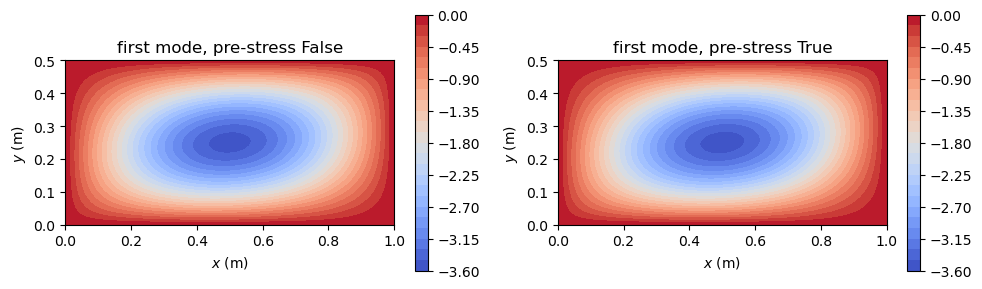

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, (prestress, (p, c)) in zip(axes, first_modes.items()):
    mesh, fields = p.uvw(np.real(c), gridx=101, gridy=61)
    cf = ax.contourf(mesh['Xs'], mesh['Ys'], fields['w'], levels=30,
                     cmap='coolwarm')
    fig.colorbar(cf, ax=ax)
    ax.set_title('first mode, pre-stress %s' % prestress)
    ax.set_xlabel('$x$ (m)')
    ax.set_ylabel('$y$ (m)')
    ax.set_aspect('equal')
fig.tight_layout()
plt.show()

## References

1. A. W. Leissa, "The free vibration of rectangular plates". Journal of Sound and Vibration, 31(3):257-293, 1973. https://doi.org/10.1016/S0022-460X(73)80371-2.